# 06 - Feature Engineering and Data Quality

## Objective

Create and evaluate video-level movement features from pose-derived joint angles.

## Tasks

1. Load joint-angle data.
2. Calculate angle range and variability for each video.
3. Calculate left-right angle differences.
4. Measure feature availability and missing values.
5. Save the final video-level feature dataset.

## Limitation

These features describe estimated movement patterns. They do not independently establish exercise quality or predict injury risk.

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


In [2]:

project_folder = Path("..")
output_folder = project_folder / "outputs"

angles_path = output_folder / "joint_angles_all.csv"

angles_df = pd.read_csv(angles_path)

print("Dataset shape:", angles_df.shape)
print("Unique videos:", angles_df["video_name"].nunique())
print("Exercise categories:", angles_df["category"].nunique())

display(angles_df.head())

Dataset shape: (3005, 9)
Unique videos: 645
Exercise categories: 22


,video_name,category,frame_number,left_elbow_angle,right_elbow_angle,left_knee_angle,right_knee_angle,left_hip_angle,right_hip_angle
0,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,0,136.532366,NaN,76.303009,61.115009,167.502841,154.760229
1,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,29,119.236965,NaN,35.128447,NaN,71.053439,NaN
2,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,59,166.130163,NaN,28.303478,NaN,52.390251,NaN
3,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,89,142.758576,NaN,51.370671,NaN,124.260108,NaN
4,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,119,141.210317,NaN,51.363290,NaN,61.971812,NaN


In [ ]:
angle_columns = [
    "left_elbow_angle",
    "right_elbow_angle",
    "left_knee_angle",
    "right_knee_angle",
    "left_hip_angle",
    "right_hip_angle",
]

# Ensure temporal order
angles_df = angles_df.sort_values(
    ["video_name", "frame_number"]
).copy()

def calculate_range(series):
    if series.count() < 2:
        return np.nan
    return series.max() - series.min()

def calculate_std(series):
    if series.count() < 2:
        return np.nan
    return series.std()

grouped = angles_df.groupby(
    ["video_name", "category"]
)

feature_parts = []

for column in angle_columns:
    stats = grouped[column].agg(
        mean="mean",
        std=calculate_std,
        min_value="min",
        max_value="max",
        valid_frames="count",
    )

    stats[f"{column}_range"] = (
        stats["max_value"] - stats["min_value"]
    )

    stats = stats.rename(columns={
        "mean": f"{column}_mean",
        "std": f"{column}_std",
        "min_value": f"{column}_min",
        "max_value": f"{column}_max",
        "valid_frames": f"{column}_valid_frames",
    })

    stats = stats.drop(
        columns=[
            f"{column}_min",
            f"{column}_max",
        ]
    )

    feature_parts.append(stats)

video_features = pd.concat(
    feature_parts,
    axis=1
).reset_index()

print("Video-level feature shape:", video_features.shape)
display(video_features.head())

Video-level feature shape: (645, 26)


,video_name,category,left_elbow_angle_mean,left_elbow_angle_std,left_elbow_angle_valid_frames,left_elbow_angle_range,right_elbow_angle_mean,right_elbow_angle_std,right_elbow_angle_valid_frames,right_elbow_angle_range,...,right_knee_angle_valid_frames,right_knee_angle_range,left_hip_angle_mean,left_hip_angle_std,left_hip_angle_valid_frames,left_hip_angle_range,right_hip_angle_mean,right_hip_angle_std,right_hip_angle_valid_frames,right_hip_angle_range
0,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,141.173677,16.793604,5,46.893198,NaN,NaN,0,NaN,...,1,0.000000,95.435690,48.968756,5,115.112590,154.760229,NaN,1,0.000000
1,barbell biceps curl_1.mp4,barbell biceps curl,76.108345,79.824542,5,157.863628,88.148148,73.111877,5,146.497289,...,2,6.582896,176.201798,0.971221,4,2.226449,173.654807,0.775160,4,1.834320
2,barbell biceps curl_10.mp4,barbell biceps curl,99.887612,70.751044,5,149.209165,105.472417,62.643468,5,140.078316,...,0,NaN,176.069324,1.383614,2,1.956726,175.407887,3.469593,2,4.906746
3,barbell biceps curl_11.mp4,barbell biceps curl,111.350837,63.408958,5,123.667348,NaN,NaN,0,NaN,...,0,NaN,172.010563,3.606898,5,9.374734,NaN,NaN,0,NaN
4,barbell biceps curl_12.mp4,barbell biceps curl,78.654110,91.680820,5,172.083026,92.070697,81.817529,5,165.300345,...,5,1.847264,174.263761,1.079454,5,2.968360,173.333825,0.852843,5,1.709572


In [4]:
joint_pairs = [
    ("elbow", "left_elbow_angle_mean", "right_elbow_angle_mean"),
    ("knee", "left_knee_angle_mean", "right_knee_angle_mean"),
    ("hip", "left_hip_angle_mean", "right_hip_angle_mean"),
]

for joint, left_col, right_col in joint_pairs:
    video_features[f"{joint}_left_right_difference"] = (
        video_features[left_col] - video_features[right_col]
    ).abs()

display(
    video_features[
        [
            "video_name",
            "category",
            "elbow_left_right_difference",
            "knee_left_right_difference",
            "hip_left_right_difference",
        ]
    ].head(10).round(2)
)

,video_name,category,elbow_left_right_difference,knee_left_right_difference,hip_left_right_difference
0,Barbell_Hip_Thrust_Tutorial__gluteworkout_Adob...,hip thrust,NaN,12.62,59.32
1,barbell biceps curl_1.mp4,barbell biceps curl,12.04,2.18,2.55
2,barbell biceps curl_10.mp4,barbell biceps curl,5.58,NaN,0.66
3,barbell biceps curl_11.mp4,barbell biceps curl,NaN,NaN,NaN
4,barbell biceps curl_12.mp4,barbell biceps curl,13.42,0.11,0.93
5,barbell biceps curl_13.mp4,barbell biceps curl,NaN,1.93,1.71
6,barbell biceps curl_14.mp4,barbell biceps curl,16.87,NaN,NaN
7,barbell biceps curl_15.mp4,barbell biceps curl,31.85,NaN,NaN
8,barbell biceps curl_16.mp4,barbell biceps curl,28.77,NaN,NaN
9,barbell biceps curl_17.mp4,barbell biceps curl,5.75,NaN,NaN


In [5]:
feature_columns = video_features.select_dtypes(
    include="number"
).columns

quality_report = pd.DataFrame({
    "valid_values": video_features[feature_columns].count(),
    "missing_values": video_features[feature_columns].isna().sum(),
    "missing_percent": (
        video_features[feature_columns].isna().mean() * 100
    ).round(2),
})

display(
    quality_report.sort_values(
        "missing_percent",
        ascending=False
    )
)

,valid_values,missing_values,missing_percent
left_knee_angle_std,294,351,54.42
right_knee_angle_std,315,330,51.16
knee_left_right_difference,317,328,50.85
right_knee_angle_mean,390,255,39.53
right_knee_angle_range,390,255,39.53
left_knee_angle_mean,396,249,38.60
left_knee_angle_range,396,249,38.60
right_hip_angle_std,409,236,36.59
hip_left_right_difference,428,217,33.64
left_hip_angle_std,432,213,33.02


In [6]:

# Check how many valid sampled frames each joint has per video

valid_frame_columns = [
    "left_elbow_angle_valid_frames",
    "right_elbow_angle_valid_frames",
    "left_knee_angle_valid_frames",
    "right_knee_angle_valid_frames",
    "left_hip_angle_valid_frames",
    "right_hip_angle_valid_frames",
]

print("Total videos:", len(video_features))

for column in valid_frame_columns:
    print(f"\n{column}")
    print(video_features[column].value_counts().sort_index())

# How many videos have sufficient observations for each joint?
# We sampled 5 frames per video, so 3 means at least 3 valid observations.

print("\nVideos with at least 3 valid observations:")
for column in valid_frame_columns:
    count = (video_features[column] >= 3).sum()
    print(f"{column}: {count}/{len(video_features)}")


Total videos: 645

left_elbow_angle_valid_frames
left_elbow_angle_valid_frames
0     69
1     42
2     62
3     43
4     90
5    339
Name: count, dtype: int64

right_elbow_angle_valid_frames
right_elbow_angle_valid_frames
0     88
1     50
2     51
3     64
4     94
5    298
Name: count, dtype: int64

left_knee_angle_valid_frames
left_knee_angle_valid_frames
0    249
1    102
2     55
3     51
4     43
5    145
Name: count, dtype: int64

right_knee_angle_valid_frames
right_knee_angle_valid_frames
0    255
1     75
2     66
3     59
4     54
5    136
Name: count, dtype: int64

left_hip_angle_valid_frames
left_hip_angle_valid_frames
0    120
1     93
2     69
3     65
4     72
5    226
Name: count, dtype: int64

right_hip_angle_valid_frames
right_hip_angle_valid_frames
0    159
1     77
2     52
3     56
4     84
5    217
Name: count, dtype: int64

Videos with at least 3 valid observations:
left_elbow_angle_valid_frames: 472/645
right_elbow_angle_valid_frames: 456/645
left_knee_angle_val

In [7]:

# Create quality flags for each joint

for column in valid_frame_columns:
    joint_name = column.replace("_angle_valid_frames", "")

    video_features[f"{joint_name}_quality_ok"] = (
        video_features[column] >= 3
    )

# Summarize the percentage of videos meeting the quality threshold

quality_flag_columns = [
    column for column in video_features.columns
    if column.endswith("_quality_ok")
]

quality_summary = pd.DataFrame({
    "videos_with_sufficient_observations": [
        int(video_features[column].sum())
        for column in quality_flag_columns
    ],
    "percentage": [
        round(video_features[column].mean() * 100, 2)
        for column in quality_flag_columns
    ]
}, index=quality_flag_columns)

display(quality_summary)

print("Updated feature table shape:", video_features.shape)


,videos_with_sufficient_observations,percentage
left_elbow_quality_ok,472,73.18
right_elbow_quality_ok,456,70.70
left_knee_quality_ok,239,37.05
right_knee_quality_ok,249,38.60
left_hip_quality_ok,363,56.28
right_hip_quality_ok,357,55.35


Updated feature table shape: (645, 35)


In [8]:
# Create the output directory if it doesn't exist
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the video-level features
features_path = output_dir / "video_level_movement_features.csv"
video_features.to_csv(features_path, index=False)

# Save the joint-quality summary
quality_path = output_dir / "joint_feature_quality_summary.csv"
quality_summary.to_csv(quality_path)

print("Feature dataset saved:", features_path.resolve())
print("Quality report saved:", quality_path.resolve())
print("Feature dataset shape:", video_features.shape)


Feature dataset saved: C:\athlete-performance-injury-risk\outputs\video_level_movement_features.csv
Quality report saved: C:\athlete-performance-injury-risk\outputs\joint_feature_quality_summary.csv
Feature dataset shape: (645, 35)


In [9]:

# Compare left elbow movement across exercise categories

elbow_summary = (
    video_features
    .groupby("category")
    .agg(
        total_videos=("video_name", "nunique"),
        videos_with_usable_elbow=(
            "left_elbow_quality_ok", "sum"
        ),
        mean_elbow_angle=(
            "left_elbow_angle_mean", "mean"
        ),
        mean_elbow_range=(
            "left_elbow_angle_range", "mean"
        ),
        mean_elbow_variability=(
            "left_elbow_angle_std", "mean"
        ),
    )
    .reset_index()
)

elbow_summary["usable_video_percentage"] = (
    elbow_summary["videos_with_usable_elbow"]
    / elbow_summary["total_videos"] * 100
).round(2)

elbow_summary = elbow_summary.sort_values(
    "total_videos", ascending=False
)

display(elbow_summary)


,category,total_videos,videos_with_usable_elbow,mean_elbow_angle,mean_elbow_range,mean_elbow_variability,usable_video_percentage
0,barbell biceps curl,61,47,113.205884,126.791475,63.626540,77.05
1,bench press,60,34,133.635501,57.127851,37.013714,56.67
14,push-up,56,44,139.314286,67.721003,32.276476,78.57
20,tricep Pushdown,50,30,119.535765,95.841551,45.678331,60.00
8,lat pulldown,48,37,116.741799,108.324886,56.896004,77.08
9,lateral raise,37,33,161.061243,31.050906,14.723411,89.19
7,incline bench press,33,23,121.143601,87.144427,45.968456,69.70
3,deadlift,32,22,170.024779,21.287838,9.560919,68.75
18,squat,29,19,74.870500,77.143782,38.379707,65.52
2,chest fly machine,28,28,131.312738,77.388722,33.536031,100.00


In [10]:

# Keep videos with at least 3 valid left-elbow observations
reliable_elbow_videos = video_features[
    video_features["left_elbow_quality_ok"]
].copy()

# Summarize only videos that meet the quality threshold
elbow_summary_filtered = (
    reliable_elbow_videos
    .groupby("category")
    .agg(
        usable_videos=("video_name", "nunique"),
        mean_elbow_angle=("left_elbow_angle_mean", "mean"),
        mean_elbow_range=("left_elbow_angle_range", "mean"),
        mean_elbow_variability=("left_elbow_angle_std", "mean"),
    )
    .reset_index()
)

# Add the total number of videos in each category
category_counts = (
    video_features.groupby("category")["video_name"]
    .nunique()
    .rename("total_videos")
    .reset_index()
)

elbow_summary_filtered = elbow_summary_filtered.merge(
    category_counts,
    on="category",
    how="left"
)

elbow_summary_filtered["usable_video_percentage"] = (
    elbow_summary_filtered["usable_videos"]
    / elbow_summary_filtered["total_videos"] * 100
).round(2)

elbow_summary_filtered = elbow_summary_filtered.sort_values(
    "usable_videos", ascending=False
)

display(elbow_summary_filtered)


,category,usable_videos,mean_elbow_angle,mean_elbow_range,mean_elbow_variability,total_videos,usable_video_percentage
0,barbell biceps curl,47,113.415890,145.120435,68.895365,61,77.05
14,push-up,44,141.787874,75.847667,33.693658,56,78.57
8,lat pulldown,37,114.947381,123.074715,56.915058,48,77.08
1,bench press,34,128.107206,89.541370,41.415745,60,56.67
9,lateral raise,33,163.235112,33.664008,15.467453,37,89.19
20,tricep Pushdown,30,118.625151,106.918055,49.042407,50,60.00
2,chest fly machine,28,131.312738,77.388722,33.536031,28,100.00
7,incline bench press,23,116.125200,105.015866,48.483535,33,69.70
13,pull Up,23,122.435468,118.818995,53.753939,26,88.46
3,deadlift,22,170.370146,21.945846,9.776572,32,68.75


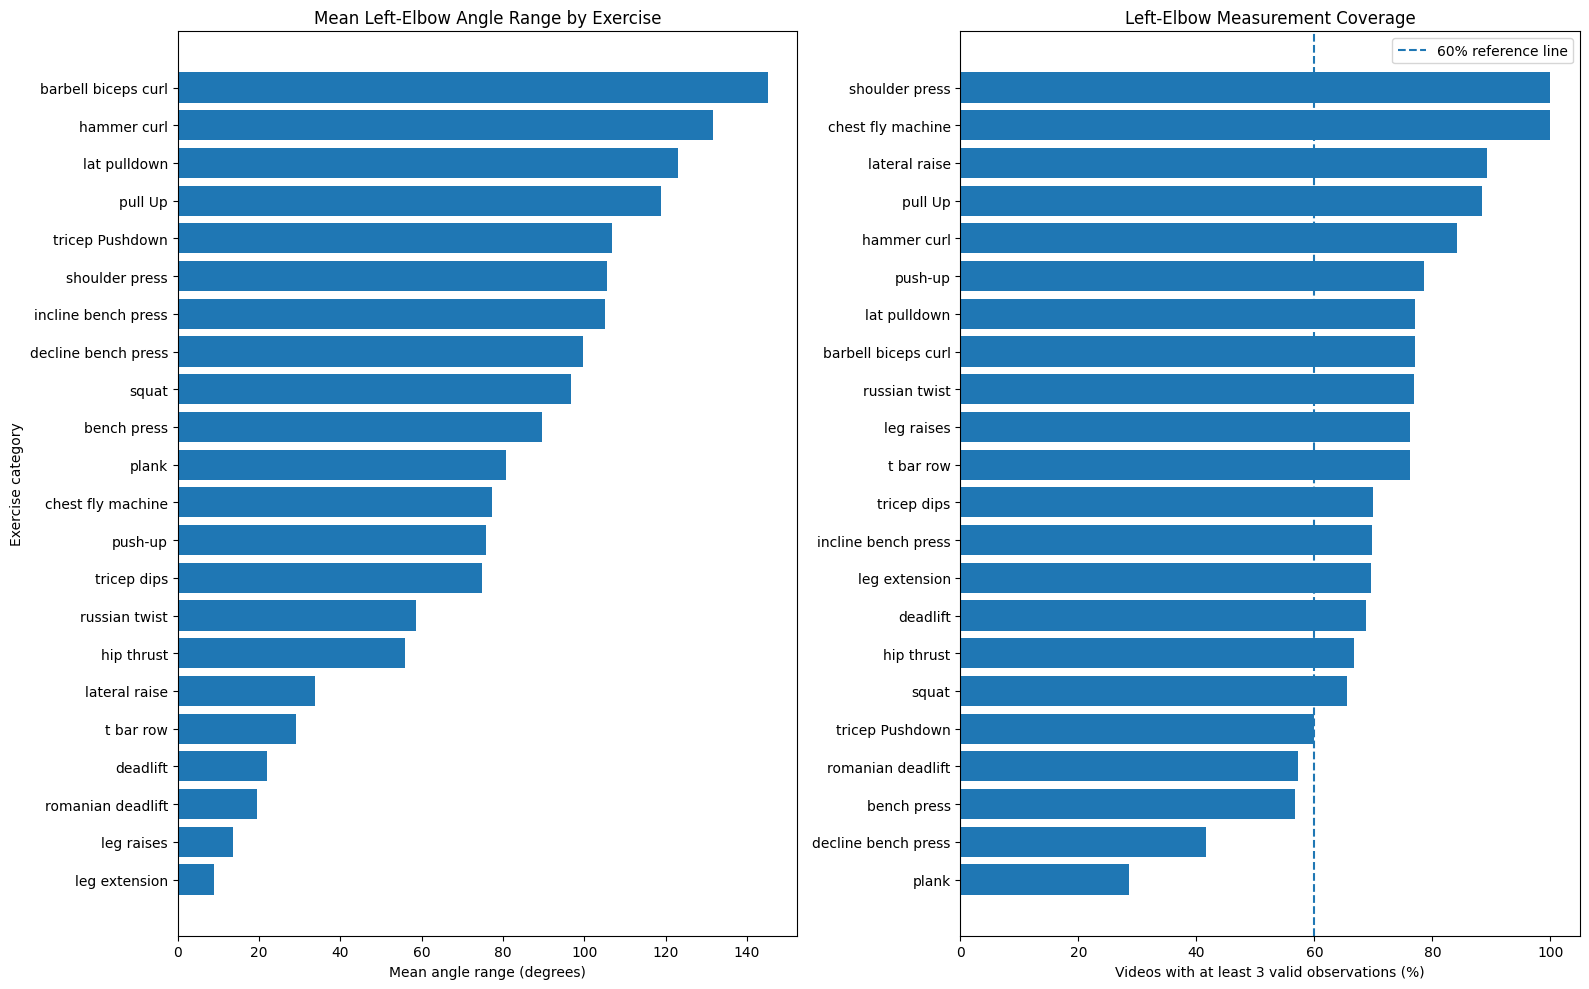

Plot saved to: C:\athlete-performance-injury-risk\outputs\exercise_elbow_quality_comparison.png


In [12]:
# Sort categories by mean elbow range for easier comparison
plot_df = elbow_summary_filtered.sort_values(
    "mean_elbow_range", ascending=True
).copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 10))

# Plot 1: Mean elbow angle range
axes[0].barh(
    plot_df["category"],
    plot_df["mean_elbow_range"]
)
axes[0].set_title("Mean Left-Elbow Angle Range by Exercise")
axes[0].set_xlabel("Mean angle range (degrees)")
axes[0].set_ylabel("Exercise category")

# Plot 2: Percentage of videos meeting the quality threshold
quality_plot_df = plot_df.sort_values(
    "usable_video_percentage", ascending=True
)

axes[1].barh(
    quality_plot_df["category"],
    quality_plot_df["usable_video_percentage"]
)
axes[1].axvline(
    60, linestyle="--",
    label="60% reference line"
)
axes[1].set_title("Left-Elbow Measurement Coverage")
axes[1].set_xlabel("Videos with at least 3 valid observations (%)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 105)
axes[1].legend()

plt.tight_layout()

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

plot_path = output_dir / "exercise_elbow_quality_comparison.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Plot saved to:", plot_path.resolve())


In [13]:

# Load the saved video-level feature dataset
feature_path = Path("../outputs/video_level_movement_features.csv")

video_features_check = pd.read_csv(feature_path)

print("Dataset shape:", video_features_check.shape)
print("Unique videos:", video_features_check["video_name"].nunique())
print("Exercise categories:", video_features_check["category"].nunique())

print("\nVideos per exercise category:")
display(
    video_features_check["category"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nDuplicate video names:",
      video_features_check["video_name"].duplicated().sum())

print("\nMissing category labels:",
      video_features_check["category"].isna().sum())


Dataset shape: (645, 35)
Unique videos: 645
Exercise categories: 22

Videos per exercise category:


category
barbell biceps curl    61
bench press            60
push-up                56
tricep Pushdown        50
lat pulldown           48
lateral raise          37
incline bench press    33
deadlift               32
squat                  29
chest fly machine      28
pull Up                26
leg extension          23
leg raises             21
t bar row              21
tricep dips            20
hammer curl            19
hip thrust             18
shoulder press         17
romanian deadlift      14
russian twist          13
decline bench press    12
plank                   7
Name: count, dtype: int64


Duplicate video names: 0

Missing category labels: 0
